In [70]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score



### Loading 2 Years of 1-Hour Bar Data into Memory

In [71]:


# Added "GC=F" for Gold Futures alongside your 5 major Forex pairs
currency_pairs = ["EURUSD=X", "USDJPY=X", "GBPUSD=X", "USDCAD=X", "AUDUSD=X", "GC=F"]
all_pairs_list = []

print("⏳ Downloading 2 years of 1-hour bars (Forex + Gold)...")
for pair in currency_pairs:
    df = yf.download(pair, period="720d", interval="1h", auto_adjust=False, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df.columns = [str(col).strip() for col in df.columns]
    
    df = df.copy()
    # Rename GC=F to XAUUSD so all charts and tables display clean ticker labels
    df["Ticker"] = "XAUUSD" if pair == "GC=F" else pair.replace("=X", "")
    df.index = df.index.tz_convert("Europe/Berlin")
    all_pairs_list.append(df)

master_df = pd.concat(all_pairs_list)
print(f"✅ Ingestion complete! Total rows loaded: {len(master_df):,}")
print(master_df.groupby("Ticker")["Close"].count())
master_df.tail(10)

⏳ Downloading 2 years of 1-hour bars (Forex + Gold)...
✅ Ingestion complete! Total rows loaded: 98,815
Ticker
AUDUSD    17107
EURUSD    17040
GBPUSD    17042
USDCAD    17115
USDJPY    16930
XAUUSD    13581
Name: Close, dtype: int64


,Adj Close,Close,High,Low,Open,Volume,Ticker
Datetime,,,,,,,
2026-11-11 19:00:00+01:00,3994.800049,3994.800049,4002.600098,3994.100098,4000.399902,8866,XAUUSD
2026-11-11 20:00:00+01:00,3993.800049,3993.800049,3998.300049,3990.500000,3994.699951,4992,XAUUSD
2026-11-11 21:00:00+01:00,3992.100098,3992.100098,3995.600098,3989.600098,3993.899902,3231,XAUUSD
2026-11-11 22:00:00+01:00,3994.300049,3994.300049,3994.600098,3989.899902,3992.199951,1660,XAUUSD
2026-11-12 00:00:00+01:00,3983.800049,3983.800049,4000.199951,3983.000000,3994.000000,0,XAUUSD
2026-11-12 01:00:00+01:00,3999.699951,3999.699951,4000.699951,3973.500000,3984.000000,6685,XAUUSD
2026-11-12 02:00:00+01:00,3990.899902,3990.899902,4005.899902,3984.199951,3999.899902,5550,XAUUSD
2026-11-12 03:00:00+01:00,3982.199951,3982.199951,3995.300049,3979.199951,3990.899902,3938,XAUUSD
2026-11-12 06:00:00+01:00,3985.100098,3985.100098,3988.399902,3974.600098,3981.000000,3411,XAUUSD


### FEATURE ENGINEERING & TRANSFORMATION MODULE

In [72]:
# =====================================================================
# FEATURE ENGINEERING & TRANSFORMATION MODULE
# =====================================================================
print("\n==================================================================")
print("             FEATURE ENGINEERING & TRANSFORMATION                ")
print("==================================================================")
print("⏳ Transforming master_df into stationary log returns and model features...")

def calculate_rsi(series, period=14):
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    return 100 - (100 / (1 + (gain / (loss + 1e-9))))

processed_chunks = []

for ticker, chunk in master_df.groupby("Ticker"):
    c = chunk.copy().sort_index()
    
    # 1. Stationary Logarithmic Returns & Lags
    c["Log_Return"] = np.log(c["Close"] / c["Close"].shift(1))
    c["Lag_1"] = c["Log_Return"].shift(1)
    c["Lag_2"] = c["Log_Return"].shift(2)
    
    # 2. Momentum & European Session Hour
    c["RSI_14"] = calculate_rsi(c["Close"])
    c["Hour"] = c.index.hour
    
    # 3. NEW: 14-Hour Rolling Volatility & 24-Hour Moving Average Distance
    c["Volatility_14"] = c["Log_Return"].rolling(window=14).std()
    sma_24 = c["Close"].rolling(window=24).mean()
    c["SMA_24_Dist"] = (c["Close"] - sma_24) / sma_24
    
    # 4. Supervised Binary Target (Next Hour Direction)
    c["Target"] = np.where(c["Log_Return"].shift(-1) > 0, 1, 0)
    processed_chunks.append(c)

master_df = pd.concat(processed_chunks).sort_index()

features = ["Lag_1", "Lag_2", "RSI_14", "Hour", "Volatility_14", "SMA_24_Dist"]
master_df.dropna(subset=features + ["Target"], inplace=True)

print(f"✅ Feature engineering complete! Clean rows ready: {len(master_df):,}")
master_df[["Ticker", "Close", "Log_Return", "RSI_14", "Volatility_14", "SMA_24_Dist", "Target"]].tail(5)





             FEATURE ENGINEERING & TRANSFORMATION                
⏳ Transforming master_df into stationary log returns and model features...
✅ Feature engineering complete! Clean rows ready: 98,677


,Ticker,Close,Log_Return,RSI_14,Volatility_14,SMA_24_Dist,Target
Datetime,,,,,,,
2026-11-12 07:00:00+01:00,EURUSD,1.107911,-0.000554,37.038023,0.000681,-0.002322,0
2026-11-12 07:00:00+01:00,USDJPY,159.796005,0.000726,46.468507,0.000530,0.001417,0
2026-11-12 07:00:00+01:00,GBPUSD,1.325486,-0.000504,26.850644,0.000505,-0.002201,0
2026-11-12 07:00:00+01:00,USDCAD,1.425840,0.000070,69.761006,0.000253,0.001112,0
2026-11-12 07:00:00+01:00,XAUUSD,3984.800049,-0.000075,20.447916,0.002199,-0.009307,0


### EDA

In [73]:
# =====================================================================
# EXPLORATORY DATA ANALYSIS (EDA) MODULE
# =====================================================================
print("\n==================================================================")
print("             EXPLORATORY DATA ANALYSIS (EDA)               ")
print("==================================================================")

# 1. SCAN MATRIX INTEGRITY & NULL FIELDS
print("\n🔍 1. DATA INTEGRITY & NULL VALUE SCAN:")
null_summary = master_df.isnull().sum()
print("• Missing value count per column:")
print(null_summary)

# 2. COMPUTE HOURLY VOLATILITY SPREAD SUMMARY STATISTICS 
print("\n📊 2. PRICE VOLATILITY STATISTICS BY TICKER:")
master_df['Hourly_Spread_Pct'] = ((master_df['High'] - master_df['Low']) / master_df['Close']) * 100
volatility_stats = master_df.groupby('Ticker')['Hourly_Spread_Pct'].describe()[['mean', 'std', 'max']]
print(volatility_stats.round(4))

# 3. CONSTRUCT INTER-ASSET CROSS-PAIR CORRELATION MATRIX
print("\n📈 3. CROSS-PAIR PRICE CORRELATION MATRIX:")
# Pivot the multi-asset layout to align columns chronologically by date
pivot_df = master_df.pivot_table(values='Close', index=master_df.index, columns='Ticker')
correlation_matrix = pivot_df.corr()
print(correlation_matrix.round(3))





             EXPLORATORY DATA ANALYSIS (EDA)               

🔍 1. DATA INTEGRITY & NULL VALUE SCAN:
• Missing value count per column:
Adj Close        0
Close            0
High             0
Low              0
Open             0
Volume           0
Ticker           0
Log_Return       0
Lag_1            0
Lag_2            0
RSI_14           0
Hour             0
Volatility_14    0
SMA_24_Dist      0
Target           0
dtype: int64

📊 2. PRICE VOLATILITY STATISTICS BY TICKER:
          mean     std     max
Ticker                        
AUDUSD  0.1465  0.1032  1.9355
EURUSD  0.1017  0.0802  1.3916
GBPUSD  0.1050  0.0745  1.2436
USDCAD  0.1167  0.0664  1.5888
USDJPY  0.1550  0.1280  2.9770
XAUUSD  0.4734  0.4262  7.6598

📈 3. CROSS-PAIR PRICE CORRELATION MATRIX:
Ticker  AUDUSD  EURUSD  GBPUSD  USDCAD  USDJPY  XAUUSD
Ticker                                                
AUDUSD   1.000   0.571   0.594  -0.332   0.522   0.700
EURUSD   0.571   1.000   0.935  -0.317   0.046   0.773
GBPUSD   0.

#### Cross-pair correlation Matrix :

### DATA PARTITIONING , TIME-SPLIT & MODEL TRAINING 

In [74]:
# =====================================================================
# PORTION A: DATA PARTITIONING & TEMPORAL SEPARATION
# =====================================================================
print("\n==================================================================")
print("          PORTION A: DATA PARTITIONING & TIME-SPLIT               ")
print("==================================================================")
print("⏳ Isolating features and creating chronological train/test boundaries...")

from sklearn.ensemble import RandomForestClassifier

# 1. Define Predictor Matrix (X) and Target Vector (y)
X = master_df[features]
y = master_df["Target"]

# 2. Chronological 80/20 Walk-Forward Split (Zero Data Leakage)
split_idx = int(len(master_df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 3. Train Balanced Random Forest Ensemble
final_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=5,
    class_weight="balanced",  # Prevents bullish bias during strong Gold rallies
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train, y_train)

print(f"✅ Balanced Random Forest trained on {len(X_train):,} rows.")
print(f"📊 Out-of-sample test set ready: {len(X_test):,} rows.")




          PORTION A: DATA PARTITIONING & TIME-SPLIT               
⏳ Isolating features and creating chronological train/test boundaries...
✅ Balanced Random Forest trained on 78,941 rows.
📊 Out-of-sample test set ready: 19,736 rows.


### Data visualization 


📈 Baseline Out-of-Sample Accuracy: 50.78%

--- Balanced Confusion Matrix ---
                 Pred Down (0)  Pred Up (1)
Actual Down (0)           5816         4385
Actual Up (1)             5330         4205

⚡ High-Confidence Results (>58%):
• Filtered Directional Accuracy: 40.00%
• High-Confidence Signals Executed: 10 / 19,736 hours


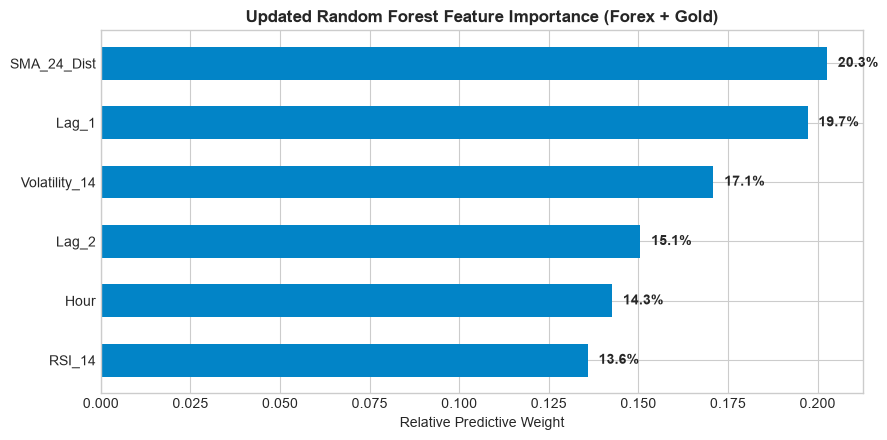

In [75]:


# 1. Baseline Predictions
raw_preds = final_model.predict(X_test)
print(f"📈 Baseline Out-of-Sample Accuracy: {accuracy_score(y_test, raw_preds)*100:.2f}%\n")

print("--- Balanced Confusion Matrix ---")
cm_df = pd.DataFrame(
    confusion_matrix(y_test, raw_preds),
    columns=["Pred Down (0)", "Pred Up (1)"],
    index=["Actual Down (0)", "Actual Up (1)"]
)
print(cm_df)

# 2. High-Confidence Threshold Filter (>58%)
prob_down = final_model.predict_proba(X_test)[:, 0]
prob_up = final_model.predict_proba(X_test)[:, 1]

CONFIDENCE_THRESHOLD = 0.58
filtered_preds, filtered_actuals = [], []

for i in range(len(X_test)):
    if prob_up[i] > CONFIDENCE_THRESHOLD:
        filtered_preds.append(1)
        filtered_actuals.append(y_test.iloc[i])
    elif prob_down[i] > CONFIDENCE_THRESHOLD:
        filtered_preds.append(0)
        filtered_actuals.append(y_test.iloc[i])

print(f"\n⚡ High-Confidence Results (>{CONFIDENCE_THRESHOLD*100:.0f}%):")
if len(filtered_preds) > 0:
    filt_acc = accuracy_score(filtered_actuals, filtered_preds)
    print(f"• Filtered Directional Accuracy: {filt_acc*100:.2f}%")
    print(f"• High-Confidence Signals Executed: {len(filtered_preds):,} / {len(X_test):,} hours")
else:
    print("⚠️ No hours crossed 58%. Lower CONFIDENCE_THRESHOLD to 0.55.")

# 3. Updated Feature Importance Bar Chart
importances = final_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(9, 4.5))
plt.barh([features[i] for i in indices], importances[indices], color="#0284C7", height=0.55)
plt.title("Updated Random Forest Feature Importance (Forex + Gold)", fontsize=12, weight="bold")
plt.xlabel("Relative Predictive Weight")
for idx, val in enumerate(importances[indices]):
    plt.text(val + 0.003, idx, f"{val*100:.1f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.savefig("03_updated_feature_importance.png", dpi=300)
plt.show()


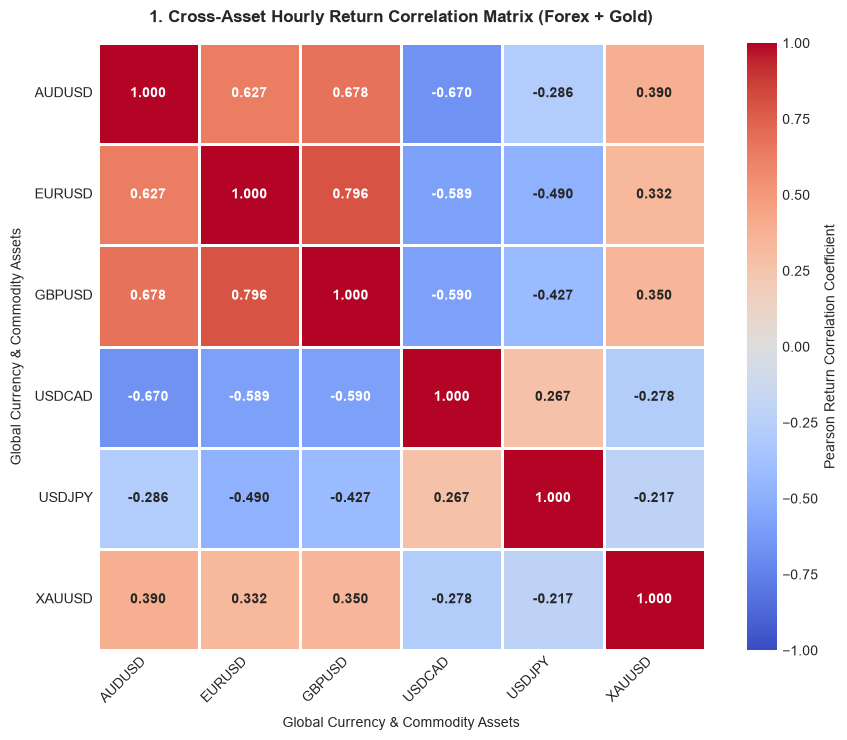

In [76]:


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

pivot_returns = master_df.pivot_table(values="Log_Return", index=master_df.index, columns="Ticker")
corr_matrix = pivot_returns.corr()

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1.0,
    vmax=1.0,
    center=0,
    linewidths=1.0,
    square=True,
    cbar_kws={"label": "Pearson Return Correlation Coefficient"},
    annot_kws={"size": 10, "weight": "bold"}
)

plt.title("1. Cross-Asset Hourly Return Correlation Matrix (Forex + Gold)", fontsize=12, weight="bold", pad=15)
plt.xlabel("Global Currency & Commodity Assets", fontsize=10, labelpad=8)
plt.ylabel("Global Currency & Commodity Assets", fontsize=10, labelpad=8)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("01_cross_asset_correlation.png", dpi=300)
plt.show()


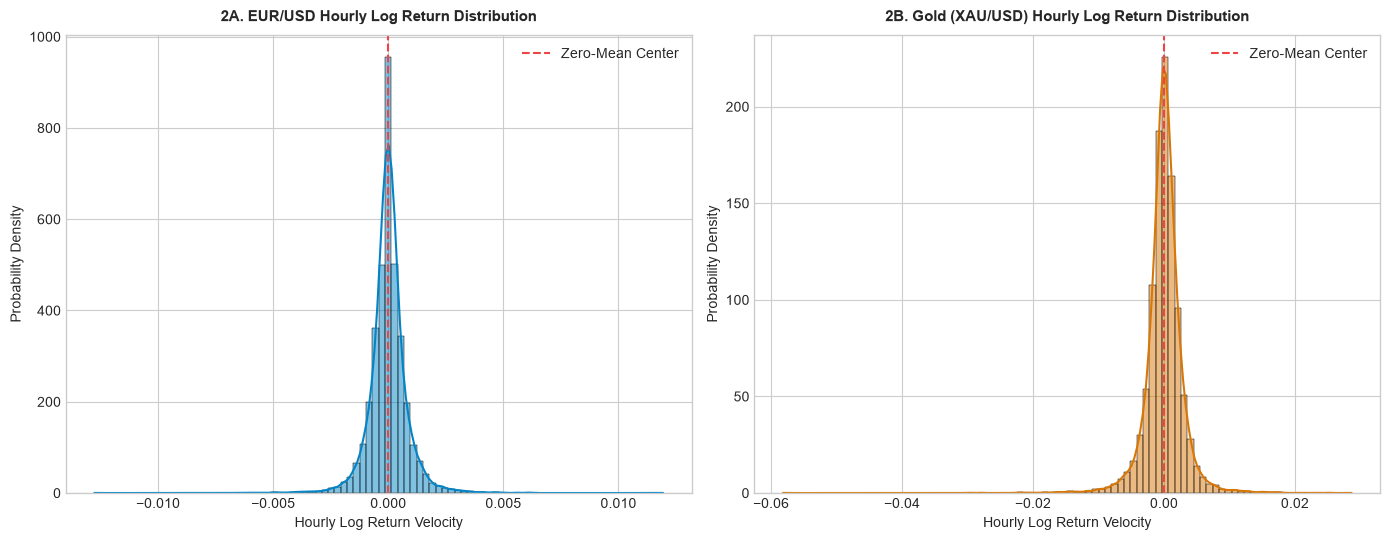

In [77]:

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: EUR/USD Log Returns
eur_returns = master_df[master_df["Ticker"] == "EURUSD"]["Log_Return"]
sns.histplot(eur_returns, kde=True, color="#0284C7", bins=90, stat="density", ax=axes[0])
axes[0].axvline(0, color="#EF4444", linestyle="--", linewidth=1.5, label="Zero-Mean Center")
axes[0].set_title("2A. EUR/USD Hourly Log Return Distribution", fontsize=11, weight="bold", pad=10)
axes[0].set_xlabel("Hourly Log Return Velocity")
axes[0].set_ylabel("Probability Density")
axes[0].legend(loc="upper right")

# Right Panel: Gold (XAU/USD) Log Returns
gold_returns = master_df[master_df["Ticker"] == "XAUUSD"]["Log_Return"]
sns.histplot(gold_returns, kde=True, color="#D97706", bins=90, stat="density", ax=axes[1])
axes[1].axvline(0, color="#EF4444", linestyle="--", linewidth=1.5, label="Zero-Mean Center")
axes[1].set_title("2B. Gold (XAU/USD) Hourly Log Return Distribution", fontsize=11, weight="bold", pad=10)
axes[1].set_xlabel("Hourly Log Return Velocity")
axes[1].set_ylabel("Probability Density")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("02_stationarity_distributions.png", dpi=300)
plt.show()


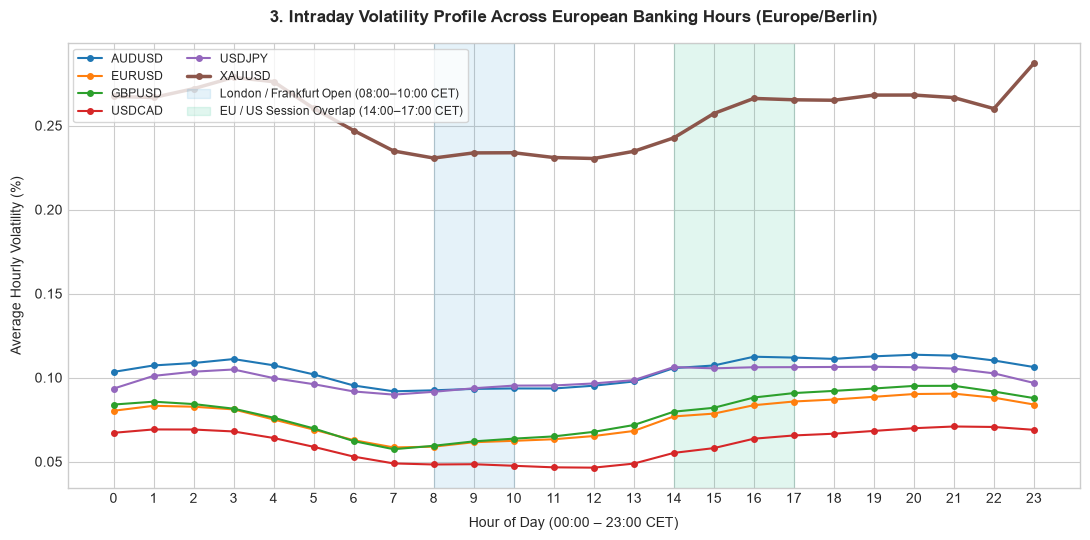

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Compute average 14-hour rolling volatility by European Hour of Day
hourly_vol = master_df.groupby(["Hour", "Ticker"])["Volatility_14"].mean().unstack() * 100

plt.figure(figsize=(11, 5.5))
for col in hourly_vol.columns:
    lw = 2.5 if col == "XAUUSD" else 1.5
    plt.plot(hourly_vol.index, hourly_vol[col], marker="o", markersize=4, linewidth=lw, label=col)

# Highlight key European & US institutional session overlaps
plt.axvspan(8, 10, color="#0284C7", alpha=0.10, label="London / Frankfurt Open (08:00–10:00 CET)")
plt.axvspan(14, 17, color="#10B981", alpha=0.12, label="EU / US Session Overlap (14:00–17:00 CET)")

plt.title("3. Intraday Volatility Profile Across European Banking Hours (Europe/Berlin)", fontsize=12, weight="bold", pad=15)
plt.xlabel("Hour of Day (00:00 – 23:00 CET)", fontsize=10, labelpad=8)
plt.ylabel("Average Hourly Volatility (%)", fontsize=10, labelpad=8)
plt.xticks(range(0, 24))
plt.legend(loc="upper left", ncol=2, fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig("03_european_session_volatility.png", dpi=300)
plt.show()


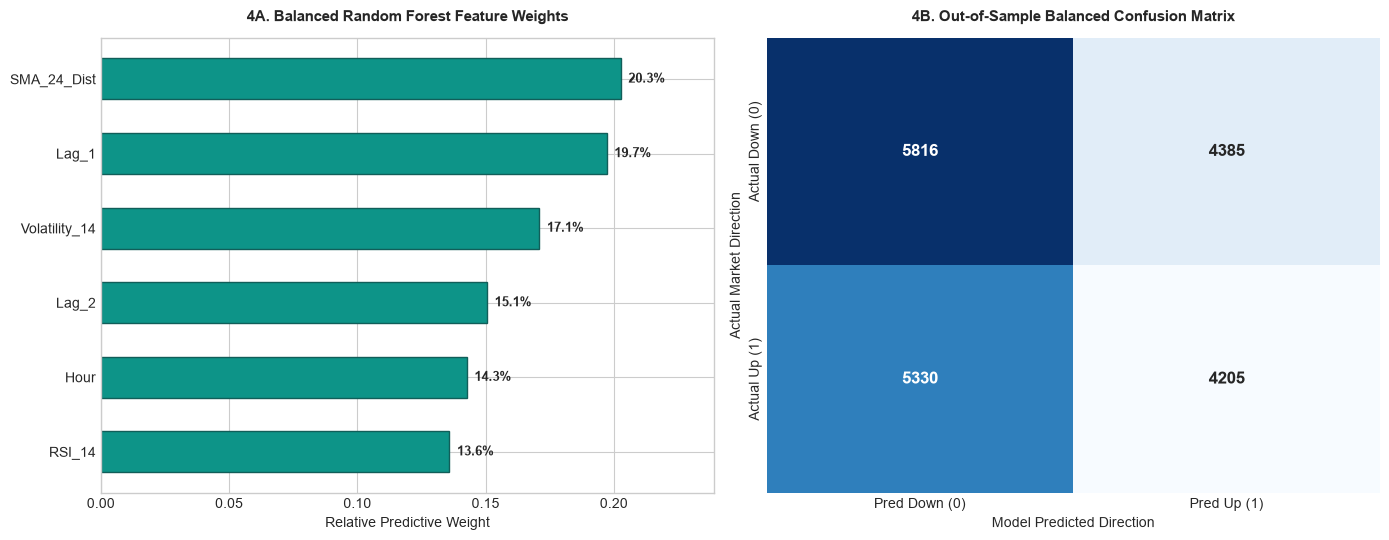

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: 6-Feature Importance Rankings
importances = final_model.feature_importances_
indices = np.argsort(importances)
sorted_feats = [features[i] for i in indices]
sorted_imps = importances[indices]

axes[0].barh(sorted_feats, sorted_imps, color="#0D9488", edgecolor="#115E59", height=0.55)
axes[0].set_title("4A. Balanced Random Forest Feature Weights", fontsize=11, weight="bold", pad=12)
axes[0].set_xlabel("Relative Predictive Weight")
axes[0].set_xlim(0, max(sorted_imps) * 1.18)

for idx, val in enumerate(sorted_imps):
    axes[0].text(val + 0.003, idx, f"{val*100:.1f}%", va="center", fontsize=9.5, weight="bold")

# Right Panel: Out-of-Sample Confusion Matrix Heatmap
raw_preds = final_model.predict(X_test)
cm = confusion_matrix(y_test, raw_preds)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred Down (0)", "Pred Up (1)"],
    yticklabels=["Actual Down (0)", "Actual Up (1)"],
    annot_kws={"size": 12, "weight": "bold"},
    ax=axes[1]
)
axes[1].set_title("4B. Out-of-Sample Balanced Confusion Matrix", fontsize=11, weight="bold", pad=12)
axes[1].set_xlabel("Model Predicted Direction")
axes[1].set_ylabel("Actual Market Direction")

plt.tight_layout()
plt.savefig("04_model_weights_and_confusion_matrix.png", dpi=300)
plt.show()
